# SVM: Weighted samples: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/svm/plot_weighted_samples.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/svm/plot_weighted_samples.html)).

**Scenario:** an imbalanced two-class `make_classification(n_samples=1000, weights=[0.9, 0.1], random_state=0)`
problem fitted by `SVC(gamma=1)` without weights and with random sample weights that are 15x larger on the
positive class; the decision function is drawn over the plotted points.

Extra checks beyond the plot: support arrays, `dual_coef_`, `intercept_`, `n_iter_` and the decision grid for both
fits; `class_weight="balanced"` and an explicit `{1: 15}` class weight; Platt scaling with
`probability=True, random_state=0` (internal 5-fold CV: `probA_`, `probB_`, `predict_proba`,
`predict_log_proba`); weighted `score`; and the other kernel estimators on the weighted data:
`NuSVC(gamma=1, nu=0.1)` and `OneClassSVM(gamma=1, nu=0.1)` (`decision_function`, `score_samples`,
`offset_`, `predict`).

**Adaptations:**
- `DecisionBoundaryDisplay.from_estimator` is matplotlib/sklearn plotting glue. Its 100 x 100 grid
  (`eps=1.0` around `X_plot`) is built in Python, shared, evaluated by Moxie's `decision_function`, and drawn
  with `contourf` exactly as the display would (`plot_method="contourf"`).
- Labels are shared as integers and fitted with `SVC[Int]`/`NuSVC[Int]`.
- `probability=True` is deprecated in the pinned revision (FutureWarning) but still supported; Moxie keeps
  the same `"deprecated"` default. Class weights use the typed `ClassWeight[Int]([1], [15.0])`.
- Figures are smaller (dpi 80).

**Determinism:** deterministic. Data and weights are seeded. The only RNG use is Platt scaling's fold shuffle,
seeded with `random_state=0`; Moxie reproduces NumPy's MT19937 draw (`randint(INT_MAX)`) and LIBSVM's
internal `rand()` stream, so probabilities are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("svm/plot_weighted_samples")

## 1. scikit-learn (Python reference)

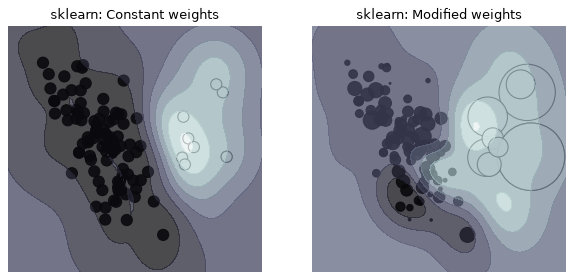

weighted score: 0.9188796103294331
probA_, probB_: [-2.03602405] [-2.14308616]


/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/deprecation.py:109: FutureWarning: Attribute `probA_` was deprecated in version 1.9 and will be removed in 1.11 as the `probability=True` option for SVC and NuSVC was deprecated and will be removed in 1.11.
  warnings.warn(msg, category=FutureWarning)
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/deprecation.py:109: FutureWarning: Attribute `probB_` was deprecated in version 1.9 and will be removed in 1.11 as the `probability=True` option for SVC and NuSVC was deprecated and will be removed in 1.11.
  warnings.warn(msg, category=FutureWarning)


In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_classification
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC

X, y = make_classification(
    n_samples=1_000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.1,
    weights=[0.9, 0.1],
    random_state=0,
)
rng = np.random.RandomState(0)
plot_indices = rng.choice(np.arange(X.shape[0]), size=100, replace=True)
X_plot, y_plot = X[plot_indices], y[plot_indices]


def plot_decision_function(classifier, sample_weight, axis, title):
    """Plot the synthetic data and the classifier decision function. Points with
    larger sample_weight are mapped to larger circles in the scatter plot."""
    axis.scatter(
        X_plot[:, 0],
        X_plot[:, 1],
        c=y_plot,
        s=100 * sample_weight[plot_indices],
        alpha=0.9,
        cmap=plt.cm.bone,
        edgecolors="black",
    )
    DecisionBoundaryDisplay.from_estimator(
        classifier,
        X_plot,
        response_method="decision_function",
        alpha=0.75,
        ax=axis,
        cmap=plt.cm.bone,
    )
    axis.axis("off")
    axis.set_title(title)


# we define constant weights as expected by the plotting function
sample_weight_constant = np.ones(len(X))
# assign random weights to all points
sample_weight_modified = abs(rng.randn(len(X)))
# assign bigger weights to the positive class
positive_class_indices = np.asarray(y == 1).nonzero()[0]
sample_weight_modified[positive_class_indices] *= 15

# This model does not include sample weights.
clf_no_weights = SVC(gamma=1)
clf_no_weights.fit(X, y)

# This other model includes sample weights.
clf_weights = SVC(gamma=1)
clf_weights.fit(X, y, sample_weight=sample_weight_modified)

fig, axes = plt.subplots(1, 2, figsize=(9, 4), dpi=80)
plot_decision_function(
    clf_no_weights, sample_weight_constant, axes[0], "sklearn: Constant weights"
)
plot_decision_function(clf_weights, sample_weight_modified, axes[1], "sklearn: Modified weights")

plt.show()

# The DecisionBoundaryDisplay grid (grid_resolution=100, eps=1.0), shared with Moxie.
x0, x1 = X_plot[:, 0], X_plot[:, 1]
xx0, xx1 = np.meshgrid(np.linspace(x0.min() - 1.0, x0.max() + 1.0, 100),
                       np.linspace(x1.min() - 1.0, x1.max() + 1.0, 100))
grid = np.c_[xx0.ravel(), xx1.ravel()]

from sklearn.svm import NuSVC, OneClassSVM
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)  # probability=True is deprecated in 1.9
    prob = SVC(gamma=1, probability=True, random_state=0).fit(X, y, sample_weight=sample_weight_modified)
balanced = SVC(gamma=1, class_weight="balanced").fit(X, y)
explicit = SVC(gamma=1, class_weight={1: 15}).fit(X, y)
nusvc = NuSVC(gamma=1, nu=0.1).fit(X, y, sample_weight=sample_weight_modified)
ocsvm = OneClassSVM(gamma=1, nu=0.1).fit(X, sample_weight=sample_weight_modified)
print("weighted score:", clf_weights.score(X, y, sample_weight=sample_weight_modified))
print("probA_, probB_:", prob.probA_, prob.probB_)
nb.share(X=X, y=y.astype(np.int64), w=sample_weight_modified, grid=grid)

## 2. Moxie (native Mojo)

In [3]:
%%mojo weighted
import numojo as nm
from moxie.svm import SVC, NuSVC, OneClassSVM, ClassWeight, Probability
from moxie_nb_io import load, load_ints, save, save_ints, save_floats


def record(tag: String, svm: SVC[Int], grid: nm.NDArray[DType.float64]) raises:
    save(tag + "_grid", svm.decision_function(grid))
    save(tag + "_support", svm.support_)
    save(tag + "_n_support", svm.n_support_)
    save(tag + "_dual_coef", svm.dual_coef_)
    save(tag + "_intercept", svm.intercept_)
    save(tag + "_n_iter", svm.n_iter_)
    save(tag + "_class_weight", svm.class_weight_)


def main() raises:
    var X = load("X")
    var y = load_ints("y")
    var w = load("w")
    var grid = load("grid")
    var clf_no_weights = SVC[Int](gamma=1.0)
    _ = clf_no_weights.fit(X, y)
    record("plain", clf_no_weights, grid)
    var clf_weights = SVC[Int](gamma=1.0)
    _ = clf_weights.fit(X, y, w.copy())
    record("weighted", clf_weights, grid)
    save_floats("weighted_score", [clf_weights.score(X, y, w.copy())])
    save_ints("weighted_pred", clf_weights.predict(X))

    var prob = SVC[Int](gamma=1.0, probability=Probability(True), random_state=0)
    _ = prob.fit(X, y, w.copy())
    save("probA", prob.probA_)
    save("probB", prob.probB_)
    save("proba", prob.predict_proba(grid))
    save("log_proba", prob.predict_log_proba(grid))
    save_ints("prob_pred", prob.predict(grid))

    var balanced = SVC[Int](gamma=1.0, class_weight="balanced")
    _ = balanced.fit(X, y)
    record("balanced", balanced, grid)
    var labels: List[Int] = [1]
    var values: List[Float64] = [15.0]
    var explicit = SVC[Int](gamma=1.0, class_weight=ClassWeight[Int](labels, values))
    _ = explicit.fit(X, y)
    record("explicit", explicit, grid)

    var nusvc = NuSVC[Int](gamma=1.0, nu=0.1)
    _ = nusvc.fit(X, y, w.copy())
    save("nu_grid", nusvc.decision_function(grid))
    save("nu_support", nusvc.support_)
    save("nu_dual_coef", nusvc.dual_coef_)
    save("nu_intercept", nusvc.intercept_)

    var ocsvm = OneClassSVM(gamma=1.0, nu=0.1)
    _ = ocsvm.fit(X, sample_weight=w.copy())
    save("oc_decision", ocsvm.decision_function(grid))
    save("oc_score_samples", ocsvm.score_samples(grid))
    save("oc_offset", ocsvm.offset_)
    save("oc_predict", ocsvm.predict(grid))
    save("oc_support", ocsvm.support_)
    print("done")

done


## 3. Side by side and parity

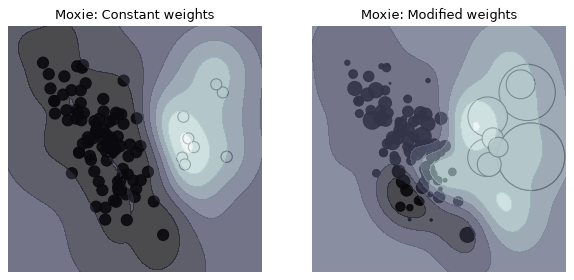

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/deprecation.py:109: FutureWarning: Attribute `probA_` was deprecated in version 1.9 and will be removed in 1.11 as the `probability=True` option for SVC and NuSVC was deprecated and will be removed in 1.11.
  warnings.warn(msg, category=FutureWarning)
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/utils/deprecation.py:109: FutureWarning: Attribute `probB_` was deprecated in version 1.9 and will be removed in 1.11 as the `probability=True` option for SVC and NuSVC was deprecated and will be removed in 1.11.
  warnings.warn(msg, category=FutureWarning)


check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
plain: decision grid,PASS,"(10000,)","(10000,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM C-SVC SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so duals differ by rounding only (family parity bound rtol 3e-5 / atol 3e-6)"
plain: support_,PASS,"(102,)","(102,)",,,exact,0 mismatches,
plain: n_support_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
plain: dual_coef_,PASS,"(1, 102)","(1, 102)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM C-SVC SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so duals differ by rounding only (family parity bound rtol 3e-5 / atol 3e-6)"
plain: intercept_,PASS,"(1,)","(1,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM C-SVC SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so duals differ by rounding only (family parity bound rtol 3e-5 / atol 3e-6)"
plain: n_iter_,PASS,"(1,)","(1,)",,,exact,0 mismatches,
plain: class_weight_,PASS,"(2,)","(2,)",0,0,"rtol=1e-14, atol=0",,n / (k * count) evaluated in the same order; last-bit rounding allowed
weighted: decision grid,PASS,"(10000,)","(10000,)",0,0,"rtol=3e-05, atol=3e-06",,"same LIBSVM C-SVC SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different summation order, so duals differ by rounding only (family parity bound rtol 3e-5 / atol 3e-6)"
weighted: support_,PASS,"(326,)","(326,)",,,exact,0 mismatches,
weighted: n_support_,PASS,"(2,)","(2,)",,,exact,0 mismatches,


In [4]:
mx = nb.results["weighted"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4), dpi=80)
for ax, tag, sw, title in ((axes[0], "plain", sample_weight_constant, "Moxie: Constant weights"),
                           (axes[1], "weighted", sample_weight_modified, "Moxie: Modified weights")):
    ax.scatter(X_plot[:, 0], X_plot[:, 1], c=y_plot, s=100 * sw[plot_indices], alpha=0.9,
               cmap=plt.cm.bone, edgecolors="black")
    ax.contourf(xx0, xx1, mx[f"{tag}_grid"].reshape(xx0.shape), alpha=0.75, cmap=plt.cm.bone)
    ax.axis("off"); ax.set_title(title)
plt.show()

moxie_nb.side_by_side(sklearn_probA=prob.probA_, moxie_probA=mx["probA"],
                      sklearn_probB=prob.probB_, moxie_probB=mx["probB"])

SOLVER = ("same LIBSVM C-SVC SMO in Float64, tol=1e-3; kernel sums and gradient updates use a different "
          "summation order, so duals differ by rounding only (family parity bound rtol 3e-5 / atol 3e-6)")
for tag, sk in (("plain", clf_no_weights), ("weighted", clf_weights), ("balanced", balanced), ("explicit", explicit)):
    nb.compare(f"{tag}: decision grid", sk.decision_function(grid), mx[f"{tag}_grid"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"{tag}: support_", sk.support_, mx[f"{tag}_support"], exact=True)
    nb.compare(f"{tag}: n_support_", sk.n_support_, mx[f"{tag}_n_support"], exact=True)
    nb.compare(f"{tag}: dual_coef_", sk.dual_coef_, mx[f"{tag}_dual_coef"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"{tag}: intercept_", sk.intercept_, mx[f"{tag}_intercept"], rtol=3e-5, atol=3e-6, reason=SOLVER)
    nb.compare(f"{tag}: n_iter_", sk.n_iter_, mx[f"{tag}_n_iter"], exact=True)
    nb.compare(f"{tag}: class_weight_", sk.class_weight_, mx[f"{tag}_class_weight"], rtol=1e-14,
               reason="n / (k * count) evaluated in the same order; last-bit rounding allowed")
nb.compare("weighted: predict(X)", clf_weights.predict(X), mx["weighted_pred"], exact=True)
nb.compare("weighted: score with sample_weight", [clf_weights.score(X, y, sample_weight=sample_weight_modified)],
           mx["weighted_score"], rtol=1e-12, reason="weighted accuracy of identical predictions; sum order")
PLATT = ("Platt sigmoid fitted by Newton iterations on 5-fold CV decision values from the same seeded "
         "fold permutation; inherits the SMO rounding bound above (rtol 3e-5 / atol 3e-6)")
nb.compare("probability: probA_", prob.probA_, mx["probA"], rtol=3e-5, atol=3e-6, reason=PLATT)
nb.compare("probability: probB_", prob.probB_, mx["probB"], rtol=3e-5, atol=3e-6, reason=PLATT)
nb.compare("probability: predict_proba(grid)", prob.predict_proba(grid), mx["proba"], rtol=3e-5, atol=3e-6, reason=PLATT)
nb.compare("probability: predict_log_proba(grid)", prob.predict_log_proba(grid), mx["log_proba"], rtol=3e-5, atol=3e-6, reason=PLATT)
nb.compare("probability: predict(grid) uses decision, not proba", prob.predict(grid), mx["prob_pred"], exact=True)
nb.compare("NuSVC: decision grid", nusvc.decision_function(grid), mx["nu_grid"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("NuSVC: support_", nusvc.support_, mx["nu_support"], exact=True)
nb.compare("NuSVC: dual_coef_", nusvc.dual_coef_, mx["nu_dual_coef"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("NuSVC: intercept_", nusvc.intercept_, mx["nu_intercept"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("OneClassSVM: decision_function(grid)", ocsvm.decision_function(grid), mx["oc_decision"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("OneClassSVM: score_samples(grid)", ocsvm.score_samples(grid), mx["oc_score_samples"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("OneClassSVM: offset_", ocsvm.offset_, mx["oc_offset"], rtol=3e-5, atol=3e-6, reason=SOLVER)
nb.compare("OneClassSVM: predict(grid)", ocsvm.predict(grid), mx["oc_predict"], exact=True)
nb.compare("OneClassSVM: support_", ocsvm.support_, mx["oc_support"], exact=True)
nb.report()
nb.assert_parity()